# Detection v2: the Sethi detector on the v6 sweeps

This notebook runs all of detection v2 and shows its results:

1. **Smoke test** (`detection/v2/run_smoke.py`).
2. **Data check**: the six v6 datasets must exist. Missing ones are generated with
   `washtrade/v6/generate.py`, the same commands as `washtrade/v6/run_v6.ipynb`.
3. **Detection** on every run of every sweep, in parallel shards (`detection/v2/experiment.py`).
   Finished shards are skipped, so re-running the notebook only redoes what is missing.
4. **Results**: false positives on honest-only markets, the named scenarios, the leakage identity,
   why the closing signal fails in an active market, the gap sweep with a control-calibrated
   threshold, Algorithm 2, camouflage and wash intensity. Section 4.5 compares honest wallets'
   closing with a random walk.

The detector is v1's, unchanged (Sirolly, Ma, Kanoria and Sethi 2026, Algorithms 1 and 2):

| Config | Meaning |
|---|---|
| `paper` | Algorithm 1 with theta = 0.9; Algorithm 2 searches theta* in [0.8, 0.99] with spillover Y <= 0.1 |
| `no_propagation` | ablation: final score = initial closing score x0 (no network step) |
| `theta_hi_1` | Algorithm 2 searched in [0.8, 1.0]; same scores as `paper` |

**Truth.** A traded pair (buy leg, sell leg; pro-rata pairing within a clear) is a wash trade iff
both legs are wash orders. Trade-level metrics are volume-weighted; a wallet is flagged iff at
least one of its pairs is flagged. Unless stated otherwise, results use the `paper` config and
are means over 20 seeds.

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path


def _find_root(start):
    for p in [start, *start.parents]:
        if (p / "marketsim").is_dir() and (p / "capstone codes").is_dir():
            return p
    raise RuntimeError("repository root not found above " + str(start))


ROOT = _find_root(Path.cwd().resolve())
for p in (str(ROOT), str(ROOT / "capstone codes")):
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from washtrade.v6 import design as D
from washtrade.v6 import generate as G
from detection.v2 import experiment as X

DET2 = ROOT / "capstone codes" / "detection" / "v2"
V6 = ROOT / "capstone codes" / "washtrade" / "v6"
print("repository root:", ROOT.name, "| python", sys.version.split()[0])

repository root: wash-trading-capstone | python 3.12.5


## Configuration

In [2]:
DATA = V6 / "data"                  # holds ds_v6_<sweep>/ (written by washtrade/v6)
SEEDS = 20                          # used only if a v6 dataset has to be generated
JOBS = max(1, (os.cpu_count() or 2) - 1)    # parallel shard processes
RUN_SMOKE = True
FORCE = False                       # True = re-run detection on shards that are already done
SWEEPS = list(D.SWEEPS)
print(f"{JOBS} parallel jobs, sweeps: {SWEEPS}")

15 parallel jobs, sweeps: ['scenarios', 'bg_grid', 'gap', 'camo', 'intensity', 'price']


## 1. Smoke test

In [3]:
if RUN_SMOKE:
    t0 = time.time()
    res = subprocess.run([sys.executable, str(DET2 / "run_smoke.py")], cwd=ROOT,
                         capture_output=True, text=True, encoding="utf-8")
    lines = res.stdout.splitlines()
    fails = [l for l in lines if "[FAIL]" in l]
    print(f"{sum('[PASS]' in l for l in lines)} checks passed, {len(fails)} failed ({time.time() - t0:.0f}s)")
    print("\n".join(fails + lines[-1:]))
    if res.returncode != 0:
        print(res.stdout[-2000:], res.stderr[-2000:])
        raise RuntimeError("smoke test failed")

39 checks passed, 0 failed (6s)
RESULT: ALL PASS


## 2. v6 data (generated only if missing)

In [4]:
for sw in SWEEPS:
    root = Path(G.dataset_root(sw, out_dir=str(DATA)))
    n_design = len(D.enumerate_runs(sw, seeds=SEEDS))
    n_have = len(pd.read_csv(root / "manifest.csv")) if (root / "manifest.csv").exists() else 0
    if n_have < n_design:
        print(f"{sw}: {n_have}/{n_design} runs -> generating the rest with {JOBS} jobs")
        procs = [subprocess.Popen([sys.executable, str(V6 / "generate.py"), "run", "--sweep", sw,
                                   "--seeds", str(SEEDS), "--shard", str(i), "--n-shards", str(JOBS),
                                   "--out", str(DATA)], cwd=ROOT, stdout=subprocess.DEVNULL)
                 for i in range(JOBS)]
        for p in procs:
            p.wait()
        G.merge(sw, out_dir=str(DATA), verbose=False)
        n_have = len(pd.read_csv(root / "manifest.csv"))
    print(f"{sw:10s} {n_have}/{n_design} runs")

scenarios  1300/1300 runs
bg_grid    1440/1440 runs
gap        1200/1200 runs
camo       1560/1560 runs
intensity  600/600 runs
price      360/360 runs


## 3. Run the detector on every sweep

In [5]:
X.run_all(SWEEPS, jobs=JOBS, data=str(DATA), force=FORCE)

scenarios  done (56s)


bg_grid    done (61s)


gap        done (50s)


camo       done (70s)


intensity  done (35s)


price      done (27s)


all sweeps in 5.0 min


## 4. Results

In [6]:
def load(sw, table="results"):
    return pd.read_csv(Path(G.dataset_root(sw, out_dir=str(DATA))) / "detection_v2" / f"{table}.csv")


R = {sw: load(sw) for sw in SWEEPS}
GR = {sw: load(sw, "groups") for sw in SWEEPS}
CU = {sw: load(sw, "curves") for sw in SWEEPS}
print({sw: f"{R[sw]['run_id'].nunique()} runs" for sw in SWEEPS})

BG5 = ["thin", "thick", "active_thin", "active", "active_dense"]
BG3 = ["thin", "thick", "active"]
COLOR = {"thin": "#2a78d6", "thick": "#eb6834", "active_thin": "#eda100", "active": "#1baf7a",
         "active_dense": "#e87ba4"}
R_COLOR = {0.01: "#2a78d6", 0.003: "#eb6834", 0.001: "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 5,
})


def mean_ci(df, by, col):
    out = df.groupby(by)[col].agg(["mean", "std", "count"]).reset_index()
    out["half"] = 1.96 * out["std"].fillna(0) / np.sqrt(out["count"])
    return out


def line_ci(ax, d, x, label, color, ls="-"):
    d = d.sort_values(x)
    ax.plot(d[x], d["mean"], ls, color=color, marker="o", label=label)
    ax.fill_between(d[x], d["mean"] - d["half"], d["mean"] + d["half"], color=color, alpha=0.15,
                    linewidth=0)

{'scenarios': '1300 runs', 'bg_grid': '1440 runs', 'gap': '1200 runs', 'camo': '1560 runs', 'intensity': '600 runs', 'price': '360 runs'}


### 4.1 Honest-only markets: how much does the detector flag when there is no wash trading?

Control runs of the `scenarios` sweep. Trade FPR = share of (honest) volume flagged at theta = 0.9;
wallet FPR = share of wallets flagged; "Alg 2 fires" = share of runs where Algorithm 2 finds a
feasible theta*. `x_honest_mean` under `no_propagation` is the share of honest wallets that close
a position at least once (x0 is 0 or 1 in a single market).

In [7]:
c = R["scenarios"][R["scenarios"]["f_scenario"] == "control"]
c.groupby(["f_background", "config"]).agg(
    trade_fpr=("trade_fixed_fpr", "mean"), wallet_fpr=("wallet_fixed_fpr", "mean"),
    alg2_fires=("alg2_detects", "mean"), x_honest_mean=("x_honest_mean", "mean"),
).round(3).unstack("config").reindex(BG5)

trade_fpr                       wallet_fpr         \
config       no_propagation  paper theta_hi_1 no_propagation  paper   
f_background                                                          
thin                  0.101  0.015      0.015          0.175  0.029   
thick                 0.131  0.002      0.002          0.302  0.003   
active_thin           0.478  0.165      0.165          0.665  0.238   
active                0.668  0.403      0.403          0.813  0.512   
active_dense          0.680  0.448      0.448          0.828  0.602   

                            alg2_fires                   x_honest_mean         \
config       theta_hi_1 no_propagation paper theta_hi_1 no_propagation  paper   
f_background                                                                    
thin              0.029            0.0   0.0        0.0          0.304  0.314   
thick             0.003            0.0   0.0        0.0          0.376  0.375   
active_thin       0.238            0.0   0.0        0.0          0.677  0.684   
active            0.512            0.0   0.0        0.0          0.813  0.815   
active_dense      0.602            0.0   0.0        0.0          0.828  0.826   

                         
config       theta_hi_1  
f_background             
thin              0.314  
thick             0.375  
active_thin       0.684  
active            0.815  
active_dense      0.826

### 4.2 Named scenarios on every background

Algorithm 1 (theta = 0.9): trade recall, trade precision, trade FPR, and the threshold-free
average precision (AP) of the trade ranking.

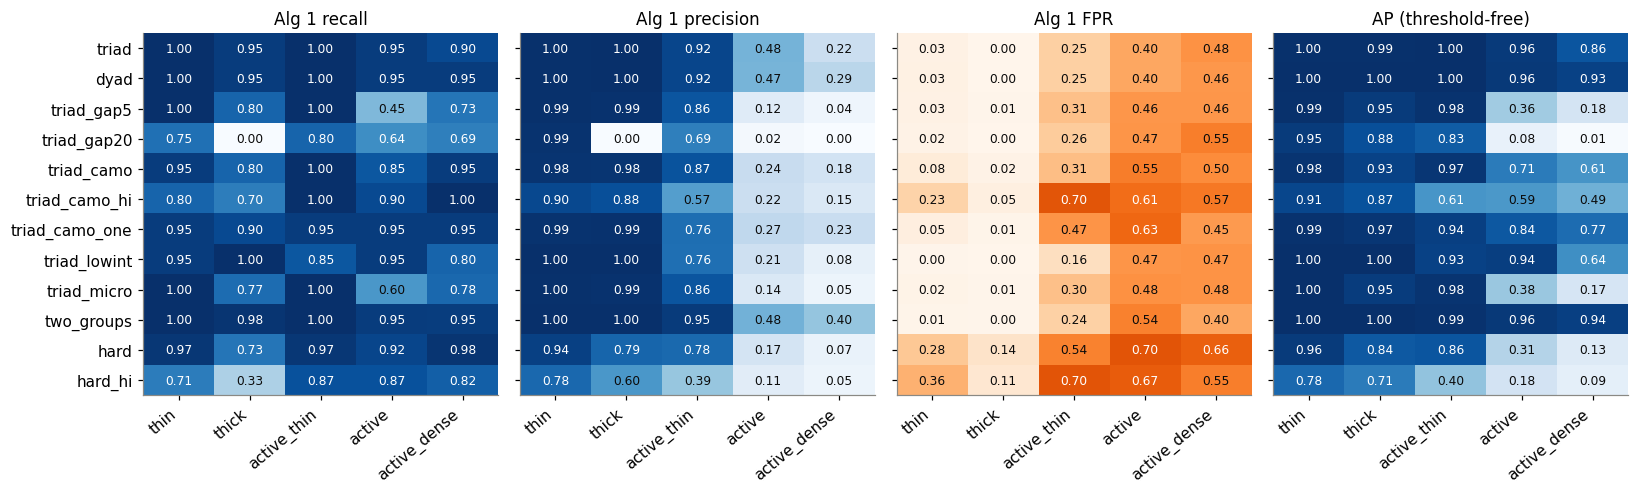

In [8]:
ORDER = ["triad", "dyad", "triad_gap5", "triad_gap20", "triad_camo", "triad_camo_hi",
         "triad_camo_one", "triad_lowint", "triad_micro", "two_groups", "hard", "hard_hi"]
p = R["scenarios"][R["scenarios"]["config"] == "paper"]
cols = [("trade_fixed_recall", "recall"), ("trade_fixed_precision", "precision"),
        ("trade_fixed_fpr", "FPR"), ("trade_avg_precision", "AP")]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), sharey=True)
for ax, (col, title) in zip(axes, cols):
    piv = p.pivot_table(index="f_scenario", columns="f_background", values=col,
                        aggfunc="mean").reindex(ORDER)[BG5]
    ax.imshow(piv.values, cmap="Blues" if col != "trade_fixed_fpr" else "Oranges",
              vmin=0, vmax=1, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(len(BG5)), BG5, rotation=40, ha="right")
    ax.set_yticks(range(len(ORDER)), ORDER)
    for (a, b), v in np.ndenumerate(piv.values):
        if np.isfinite(v):
            ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.6 else "#0b0b0b")
    ax.set_title(f"Alg 1 {title}" if col != "trade_avg_precision" else "AP (threshold-free)")
fig.tight_layout()

### 4.3 The leakage identity

For a wash group G with leakage l (share of its volume traded with outsiders, from the
detector's own pro-rata counterparty volumes), outsider score s_bar and mean initial score
x0_bar, the propagation fixed point gives

$$
\bar x = \frac{\bar x^0 + \ell\,\bar s}{1+\ell}
$$

exactly when the group's wallets share one score (the exact identity is
$\bar x = \bar x^0 + \ell(\bar s - x_{\mathrm{out}})$, checked in the smoke test). Left: the
formula against the group's actual volume-weighted score, for every group of every sweep.
Right: the same formula with the outsider score set to 0, which is what one would assume if
honest counterparties never closed positions.

5940 groups: mean |x_bar - x_pred| = 0.0006, max = 0.0256
mean outsider score s_bar by mean-reversion rate r:
r
0.001    0.833
0.003    0.599
0.010    0.478


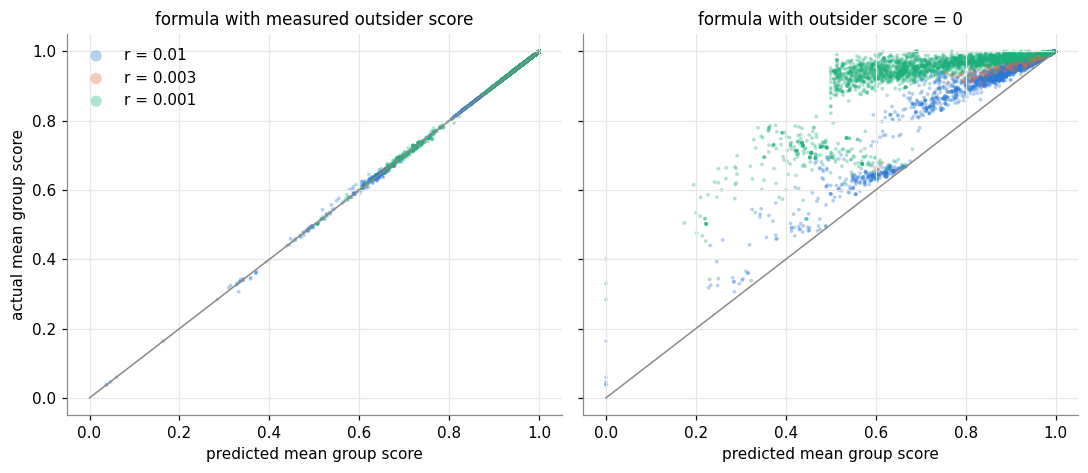

In [9]:
g = pd.concat([GR[sw].assign(sweep=sw) for sw in SWEEPS], ignore_index=True)
g = g[(g["config"] == "paper") & g["x_bar"].notna()].copy()
r_of_run = pd.concat([pd.read_csv(Path(G.dataset_root(sw, out_dir=str(DATA))) / "manifest.csv",
                                  usecols=["run_id", "r"]).assign(sweep=sw) for sw in SWEEPS])
g = g.merge(r_of_run, on=["sweep", "run_id"], how="left")
g["x_pred_s0"] = (g["x0_bar"]) / (1 + g["leak"])
err = (g["x_bar"] - g["x_pred"]).abs()
print(f"{len(g)} groups: mean |x_bar - x_pred| = {err.mean():.4f}, max = {err.max():.4f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
for ax, col, title in ((axes[0], "x_pred", "formula with measured outsider score"),
                       (axes[1], "x_pred_s0", "formula with outsider score = 0")):
    for r, color in R_COLOR.items():
        s = g[np.isclose(g["r"], r)]
        ax.scatter(s[col], s["x_bar"], s=6, alpha=0.35, color=color, label=f"r = {r:g}",
                   edgecolors="none")
    ax.plot([0, 1], [0, 1], color="#8a8984", linewidth=1)
    ax.set_xlabel("predicted mean group score")
    ax.set_title(title)
axes[0].set_ylabel("actual mean group score")
axes[0].legend(markerscale=3)
fig.tight_layout()
print("mean outsider score s_bar by mean-reversion rate r:")
print(g.groupby("r")["s_bar"].mean().round(3).to_string())

### 4.4 Why the closing signal fails in an active market

`bg_grid` control runs (no wash trading). Left: the more an honest ZI trades, the more likely it
closes a position at least once (x0 = 1). Right: once most honest wallets have x0 = 1, the
network step can no longer separate them and Algorithm 1 flags a large share of honest volume.

corr(legs per ZI, closing share) = 0.796


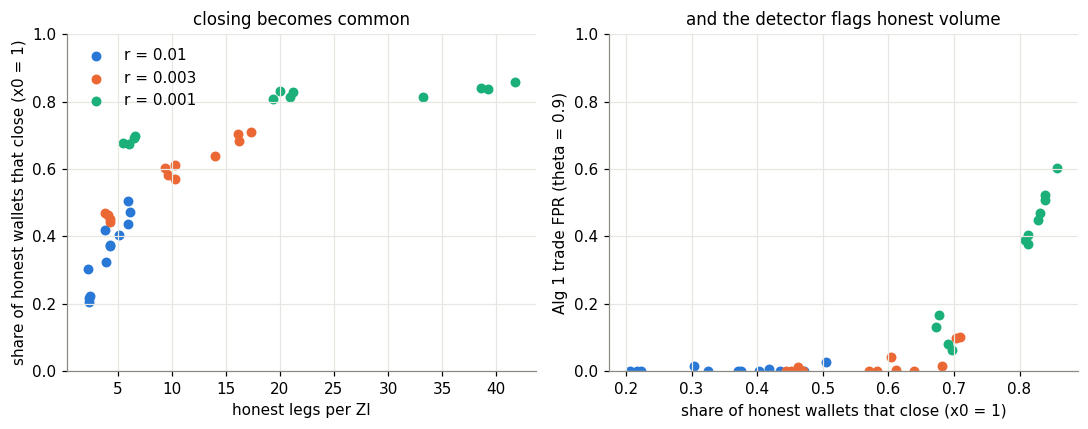

In [10]:
man = pd.read_csv(Path(G.dataset_root("bg_grid", out_dir=str(DATA))) / "manifest.csv")
bg = R["bg_grid"][R["bg_grid"]["f_scenario"] == "control"]
x0 = bg[bg["config"] == "no_propagation"][["run_id", "f_r", "x_honest_mean"]].rename(
    columns={"x_honest_mean": "honest_x0"})
fpr = bg[bg["config"] == "paper"][["run_id", "trade_fixed_fpr"]]
d = x0.merge(fpr, on="run_id").merge(man[["run_id", "background_legs_per_agent"]], on="run_id")
cell = d.merge(bg[bg["config"] == "paper"][["run_id", "f_n_zi", "f_lam"]], on="run_id").groupby(
    ["f_r", "f_n_zi", "f_lam"]).mean(numeric_only=True).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for r, color in R_COLOR.items():
    s = cell[np.isclose(cell["f_r"], r)]
    axes[0].scatter(s["background_legs_per_agent"], s["honest_x0"], color=color, s=30,
                    label=f"r = {r:g}")
    axes[1].scatter(s["honest_x0"], s["trade_fixed_fpr"], color=color, s=30, label=f"r = {r:g}")
axes[0].set_xlabel("honest legs per ZI")
axes[0].set_ylabel("share of honest wallets that close (x0 = 1)")
axes[0].set_ylim(0, 1)
axes[1].set_xlabel("share of honest wallets that close (x0 = 1)")
axes[1].set_ylabel("Alg 1 trade FPR (theta = 0.9)")
axes[1].set_ylim(0, 1)
axes[0].legend()
axes[0].set_title("closing becomes common")
axes[1].set_title("and the detector flags honest volume")
fig.tight_layout()
print("corr(legs per ZI, closing share) =",
      round(np.corrcoef(cell["background_legs_per_agent"], cell["honest_x0"])[0, 1], 3))

### 4.5 Honest positions as random walks

The market has no settlement or forced liquidation. A closure is a pattern on the tape: a
wallet's net position returns to 0 (positions are integers no larger than 10, so the paper's
rule $X_\tau \le c\,M$ with $c = 0.005$ means exactly 0). A ZI chooses buy or sell with a fair
coin, so its position is close to a simple random walk, which returns to 0 within $n$ steps with
probability

$$
P_{\text{close}}(n) = 1 - \frac{\binom{2m}{m}}{4^m}, \qquad m = \lfloor n/2 \rfloor .
$$

Honest wallets of the `bg_grid` control runs, binned by their number of position-changing trades
$n$: observed share that closed at least once vs the random-walk prediction. Dots are the observed
shares, one panel per mean-reversion rate r, and the grey curve is the prediction.

observed - random walk, over the 12 (n_zi, lam) cells of each r:
        mean    min    max
f_r                       
0.001 -0.002 -0.047  0.038
0.003 -0.122 -0.171 -0.075
0.010 -0.185 -0.224 -0.100


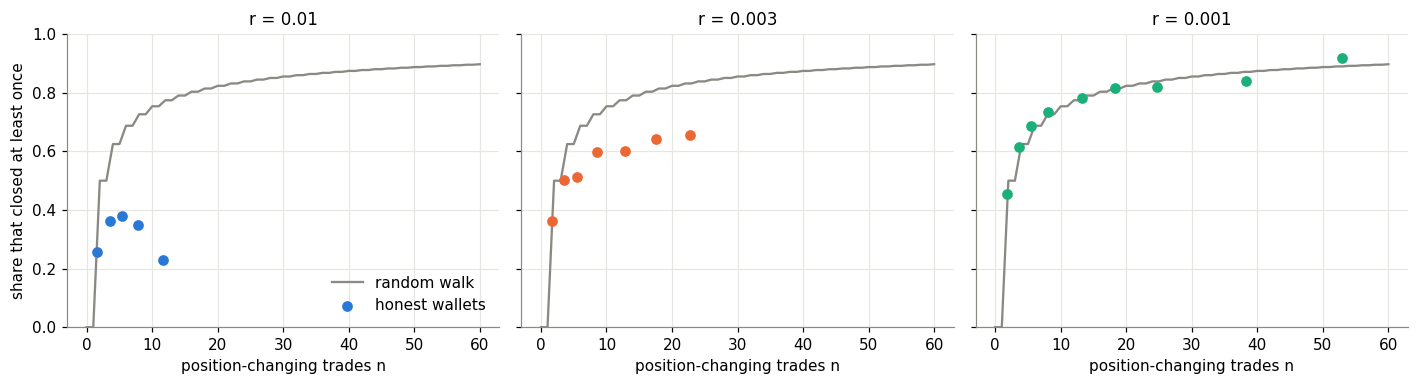

In [11]:
from detection.v2.closing import p_return

W = load("bg_grid", "wallets")
h = W[(~W["is_wash"]) & (W["f_scenario"] == "control")].copy()
bins = [0, 2, 4, 6, 10, 15, 20, 30, 50, 200]
h["bin"] = pd.cut(h["n_steps"], bins)
tab = h.groupby(["f_r", "bin"], observed=True).agg(
    n=("closed", "size"), mean_steps=("n_steps", "mean"), observed=("closed", "mean"),
    random_walk=("rw_p_close", "mean")).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
grid_n = np.arange(0, 61)
for ax, r in zip(axes, sorted(R_COLOR, reverse=True)):
    t = tab[np.isclose(tab["f_r"], r) & (tab["n"] >= 50)]
    ax.plot(grid_n, [p_return(n) for n in grid_n], color="#8a8984", linewidth=1.5,
            label="random walk")
    ax.scatter(t["mean_steps"], t["observed"], color=R_COLOR[r], s=36, zorder=3,
               label="honest wallets")
    ax.set_title(f"r = {r:g}")
    ax.set_xlabel("position-changing trades n")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("share that closed at least once")
axes[0].legend()
fig.tight_layout()
cell = h.groupby(["f_r", "f_n_zi", "f_lam"]).agg(observed=("closed", "mean"),
                                                 random_walk=("rw_p_close", "mean"))
cell["gap"] = cell["observed"] - cell["random_walk"]
print("observed - random walk, over the 12 (n_zi, lam) cells of each r:")
print(cell.groupby("f_r")["gap"].agg(["mean", "min", "max"]).round(3).to_string())

### 4.6 Gap sweep with a control-calibrated threshold

A simulation can do what the paper could not: calibrate theta on honest-only runs. For each
background, theta_cal is the smallest grid value (0.50 ... 1.00) whose pooled trade FPR on that
background's control runs is at most 1%. Solid: Algorithm 1 (theta = 0.9); dashed: theta_cal.
Pooled over seeds (volume-weighted). Triads only.

theta_cal: {'thin': 0.94, 'thick': 0.82, 'active_thin': 0.99, 'active': 0.98, 'active_dense': 0.97}


precision                                                    \
background    active                    thick                     thin   
rule       theta 0.9 theta_cal 0.98 theta 0.9 theta_cal 0.82 theta 0.9   
f_gap                                                                    
0               0.36           1.00      1.00           0.98      1.00   
1               0.26           0.98      1.00           0.98      1.00   
2               0.23           0.59      0.99           0.97      1.00   
3               0.18           0.86      1.00           0.95      1.00   
5               0.09           0.08      0.99           0.96      0.99   
8               0.08           0.07      0.99           0.88      0.99   
12              0.04           0.00      0.94           0.86      1.00   
20              0.02           0.00      0.00           0.81      0.99   
30              0.01            NaN      0.00           0.72      0.93   
50              0.00           0.00      0.00           0.59      0.83   

                             recall                                          \
background                   active                    thick                  
rule       theta_cal 0.94 theta 0.9 theta_cal 0.98 theta 0.9 theta_cal 0.82   
f_gap                                                                         
0                    1.00      0.95           0.34      0.95           0.95   
1                    1.00      0.95           0.36      1.00           1.00   
2                    1.00      0.91           0.21      1.00           1.00   
3                    1.00      0.70           0.02      0.86           0.86   
5                    0.99      0.45           0.05      0.79           0.79   
8                    1.00      0.77           0.10      0.53           0.95   
12                   1.00      0.52           0.00      0.18           0.83   
20                   0.98      0.55           0.00      0.00           0.82   
30                   0.91      0.65           0.00      0.00           0.58   
50                   0.69      0.56           0.00      0.00           0.33   

                                     
background      thin                 
rule       theta 0.9 theta_cal 0.94  
f_gap                                
0               1.00           1.00  
1               0.95           0.95  
2               0.95           0.95  
3               0.95           0.95  
5               1.00           1.00  
8               1.00           1.00  
12              0.84           0.84  
20              0.76           0.49  
30              0.48           0.22  
50              0.40           0.06

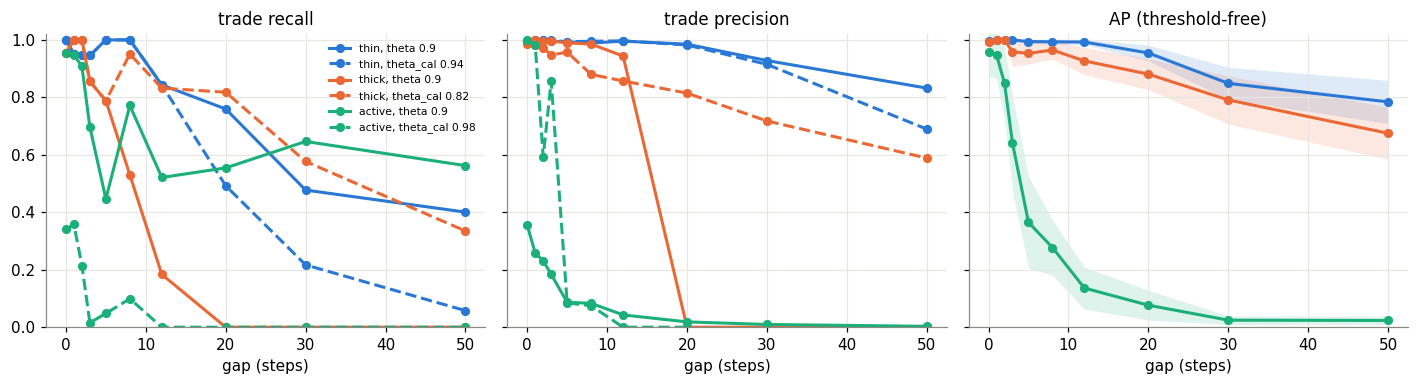

In [12]:
TARGET_FPR = 0.01
cc = CU["scenarios"]
cc = cc[(cc["config"] == "paper") & (cc["f_scenario"] == "control")]
pool = cc.groupby(["f_background", "theta"])[["trade_fp", "trade_neg"]].sum()
pool["fpr"] = pool["trade_fp"] / pool["trade_neg"]
theta_cal = {b: float(pool.loc[b][pool.loc[b]["fpr"] <= TARGET_FPR].index.min()) for b in BG5}
print("theta_cal:", theta_cal)

gc = CU["gap"]
gc = gc[(gc["config"] == "paper") & (gc["f_n_wallets"] == 3)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True, sharey=True)
summary = []
for b in BG3:
    for th, ls, tag in ((0.9, "-", "theta 0.9"), (theta_cal[b], "--", f"theta_cal {theta_cal[b]:.2f}")):
        s = gc[(gc["f_background"] == b) & np.isclose(gc["theta"], th)]
        a = s.groupby("f_gap")[["trade_tp", "trade_fp", "trade_pos"]].sum()
        rec = a["trade_tp"] / a["trade_pos"]
        prec = a["trade_tp"] / (a["trade_tp"] + a["trade_fp"])
        axes[0].plot(rec.index, rec, ls, color=COLOR[b], marker="o", label=f"{b}, {tag}")
        axes[1].plot(prec.index, prec, ls, color=COLOR[b], marker="o")
        summary.append(pd.DataFrame(dict(background=b, rule=tag, recall=rec, precision=prec)))
    ap = R["gap"][(R["gap"]["config"] == "paper") & (R["gap"]["f_n_wallets"] == 3)
                  & (R["gap"]["f_background"] == b)]
    line_ci(axes[2], mean_ci(ap, "f_gap", "trade_avg_precision"), "f_gap", b, COLOR[b])
for ax, t in zip(axes, ("trade recall", "trade precision", "AP (threshold-free)")):
    ax.set_title(t)
    ax.set_xlabel("gap (steps)")
    ax.set_ylim(0, 1.02)
axes[0].legend(fontsize=7)
fig.tight_layout()
pd.concat(summary).reset_index().pivot_table(
    index="f_gap", columns=["background", "rule"], values=["recall", "precision"]).round(2)

### 4.7 Algorithm 2: when does it commit to a threshold?

Share of wash runs (`scenarios`, all non-control scenarios) where theta* exists, and its trade
recall / precision / FPR on those runs.

In [13]:
rows = []
for cfg in ("paper", "theta_hi_1"):
    s = R["scenarios"][(R["scenarios"]["config"] == cfg) & (R["scenarios"]["f_scenario"] != "control")]
    t = s.groupby("f_background").agg(fires=("alg2_detects", "mean"))
    f = s[s["alg2_detects"]].groupby("f_background").agg(
        recall=("trade_star_recall", "mean"), precision=("trade_star_precision", "mean"),
        fpr=("trade_star_fpr", "mean"))
    rows.append(t.join(f).reindex(BG5).assign(config=cfg))
pd.concat(rows).round(3)

,fires,recall,precision,fpr,config
f_background,,,,,
thin,0.450,1.000,0.976,0.118,paper
thick,0.262,0.938,0.993,0.010,paper
active_thin,0.442,1.000,0.781,0.473,paper
active,0.033,1.000,0.201,0.888,paper
active_dense,0.000,NaN,NaN,NaN,paper
thin,0.671,0.938,0.966,0.071,theta_hi_1
thick,0.317,0.903,0.996,0.004,theta_hi_1
active_thin,0.521,0.945,0.849,0.298,theta_hi_1
active,0.058,1.000,0.355,0.722,theta_hi_1


### 4.8 Camouflage intensity and wash intensity (gap 0)

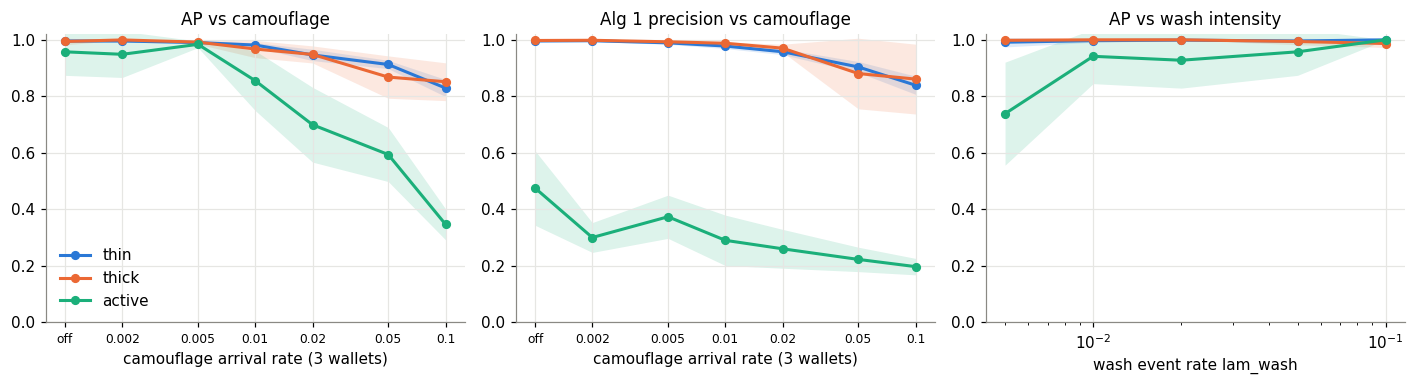

In [14]:
cm = R["camo"]
cm = cm[(cm["config"] == "paper") & (cm["f_gap"] == 0) & cm["f_n_camouflage"].isin([0, 3])]
it = R["intensity"]
it = it[(it["config"] == "paper") & (it["f_gap"] == 0)]
rates = sorted(cm.loc[cm["f_camouflage_lam"] > 0, "f_camouflage_lam"].unique())
x0 = rates[0] / 2
cm = cm.assign(x=cm["f_camouflage_lam"].where(cm["f_camouflage_lam"] > 0, x0))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for b in BG3:
    line_ci(axes[0], mean_ci(cm[cm["f_background"] == b], "x", "trade_avg_precision"), "x", b, COLOR[b])
    line_ci(axes[1], mean_ci(cm[cm["f_background"] == b], "x", "trade_fixed_precision"), "x", b, COLOR[b])
    line_ci(axes[2], mean_ci(it[it["f_background"] == b], "f_lam_wash", "trade_avg_precision"),
            "f_lam_wash", b, COLOR[b])
for ax in axes[:2]:
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks([x0] + rates, ["off"] + [f"{r:g}" for r in rates], fontsize=8)
    ax.set_xlabel("camouflage arrival rate (3 wallets)")
axes[2].set_xscale("log")
axes[2].set_xlabel("wash event rate lam_wash")
axes[0].set_title("AP vs camouflage")
axes[1].set_title("Alg 1 precision vs camouflage")
axes[2].set_title("AP vs wash intensity")
for ax in axes:
    ax.set_ylim(0, 1.02)
axes[0].legend()
fig.tight_layout()

## 5. Summary (20 seeds)

1. **The leakage identity holds.** Across every wash group the formula reproduces the group's mean
   score almost exactly (4.3). The outsider score is not near 0, though: about 0.48 in the
   r = 0.01 backgrounds and about 0.83 in the active ones. A group drops below theta only when
   $\ell > (\bar x^0-\theta)/(\theta-\bar s)$, and never when the outsiders score above theta.
2. **Why honest wallets close (4.4, 4.5).** The market has no settlement; a closure is a net
   position returning to 0. In the active market (r = 1e-3), honest positions behave like random
   walks: the share of honest wallets that close matches the random-walk prediction within a few
   points at every trade count. In the r = 0.01 market they close far less often than a random
   walk with the same number of trades, because their few trades are driven by private values and
   move in one direction. The closing signal is informative only in the second case.
3. **thin / thick (PyMarketSim's Table-3 market).** On honest-only runs Algorithm 1 flags 1.5% (thin)
   and 0.2% (thick) of volume, and recall falls as the leg gap grows. A threshold calibrated on
   control runs is 0.94 (thin) and 0.82 (thick). In thick it lifts recall at gap 20 from 0 to about
   0.8 (4.6).
4. **Active honest market (r = 1e-3).** Because most honest wallets close, Algorithm 1 flags 40-45%
   of honest volume on honest-only runs (4.1). Precision in the wash scenarios drops to 0.05-0.48,
   and AP falls from about 0.96 at gap 0 to about 0.02 at gap 50. Algorithm 2 almost never commits
   to a threshold there (4.7). That is safe, but it detects nothing, and calibrating the threshold
   does not recover recall (4.6).
5. **Camouflage** mainly hurts in the active market (4.8). **Wash intensity** barely matters on
   thin / thick.